# Análisis de sentimiento en tweets de aerolíneas con LSTM
**Autor:** Emilio Páez de la Mora — A01801224

## 1. Introducción


Las aerolíneas reciben miles de menciones diarias en redes sociales. Leerlas a mano
para detectar quejas es lento y costoso. El objetivo de este proyecto es entrenar una
red neuronal recurrente (LSTM) con Keras + TensorFlow que clasifique automáticamente
el sentimiento de un tweet como **negativo, neutral o positivo**.

**Relevancia:** un modelo así permite priorizar quejas, medir la satisfacción del
cliente en tiempo real y detectar problemas de servicio (retrasos, equipaje perdido)
antes de que escalen.

In [16]:
#importar linbrerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras

# Semilla para que los resultados se puedan repetir
SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)

print(f"Versión de TensorFlow: {tf.__version__}")

Versión de TensorFlow: 2.21.0


In [17]:
#Descargar datos
import kagglehub

# Descarga el dataset directo desde Kaggle
ruta = kagglehub.dataset_download("crowdflower/twitter-airline-sentiment")
print(f"Archivos descargados en: {ruta}")

#Cargar el CSV
import os

df = pd.read_csv(os.path.join(ruta, "Tweets.csv"))
print(f"Filas y columnas: {df.shape}")
df.head()

Using Colab cache for faster access to the 'twitter-airline-sentiment' dataset.
Archivos descargados en: /kaggle/input/twitter-airline-sentiment
Filas y columnas: (14640, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


## 2. Datos


### 2.1 Descripción y fuente
- **Dataset:** Twitter US Airline Sentiment
- **Fuente:** Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment
  (originalmente de la biblioteca *Data for Everyone* de CrowdFlower)
- **Contenido:** 14,640 tweets de febrero de 2015 dirigidos a 6 aerolíneas de EE. UU.,
  etiquetados por personas como `negative`, `neutral` o `positive`.

Para este problema solo se usan dos columnas:
- `text`: el texto del tweet (entrada del modelo)
- `airline_sentiment`: el sentimiento (lo que queremos predecir)

In [18]:
# Nos quedamos solo con el texto y la etiqueta
datos = df[["text", "airline_sentiment"]].copy()
datos.columns = ["texto", "sentimiento"]

print(f"Valores nulos:\n{datos.isnull().sum()}\n")
print(f"Tweets duplicados: {datos.duplicated().sum()}")

# Quitamos duplicados para que un mismo tweet no quede en entrenamiento y prueba a la vez
datos = datos.drop_duplicates().reset_index(drop=True)
print(f"Tweets después de quitar duplicados: {len(datos)}")

Valores nulos:
texto          0
sentimiento    0
dtype: int64

Tweets duplicados: 188
Tweets después de quitar duplicados: 14452


#### Hallazgos de la selección y limpieza inicial
- El dataset original tiene **14,640 filas y 15 columnas**. La mayoría de las columnas son
  metadatos del tweet (id, usuario, fecha, coordenadas, número de retweets) o información
  que solo existe para algunas clases, como `negativereason`, que únicamente aplica a los
  tweets negativos. Usarlas sería hacer trampa: el modelo debe predecir el sentimiento
  **solo a partir del texto**, que es lo único que tendremos para un tweet nuevo.
- Por eso se conservan únicamente `text` (entrada) y `airline_sentiment` (salida),
  renombradas a `texto` y `sentimiento`.
- Ninguna de estas dos columnas tiene **valores nulos**, por lo que no fue necesario
  eliminar ni imputar registros por falta de datos.
- Se encontraron **188 tweets duplicados** (1.3% del total), probablemente retweets o
  mensajes repetidos. Se eliminaron para evitar *data leakage*: si un mismo tweet quedara
  en entrenamiento y en prueba, el modelo "ya conocería la respuesta" y su desempeño en
  prueba saldría inflado.
- Tras este paso quedan **14,452 tweets** para el análisis.

### 2.2 Análisis exploratorio


Tweets por clase:
  negative: 9087 (62.9%)
  neutral: 3067 (21.2%)
  positive: 2298 (15.9%)


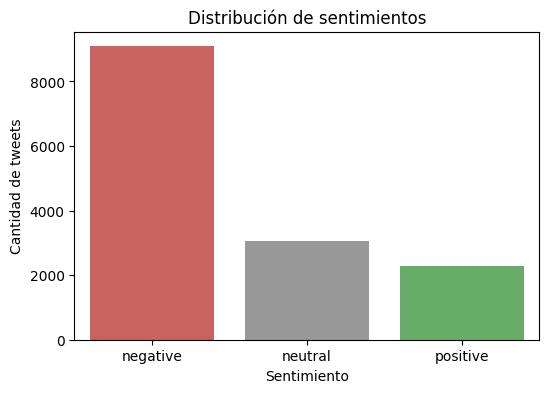

In [19]:
conteo = datos["sentimiento"].value_counts()
porcentaje = datos["sentimiento"].value_counts(normalize=True) * 100

print("Tweets por clase:")
for clase in conteo.index:
    print(f"  {clase}: {conteo[clase]} ({porcentaje[clase]:.1f}%)")

plt.figure(figsize=(6, 4))
sns.countplot(data=datos, x="sentimiento", order=conteo.index,
              hue="sentimiento", palette={"negative": "#d9534f", "neutral": "#999999", "positive": "#5cb85c"}, legend=False)
plt.title("Distribución de sentimientos")
plt.xlabel("Sentimiento")
plt.ylabel("Cantidad de tweets")
plt.show()

count    14452.000000
mean        17.711043
std          6.835783
min          2.000000
25%         13.000000
50%         19.000000
75%         23.000000
max         36.000000
Name: num_palabras, dtype: float64


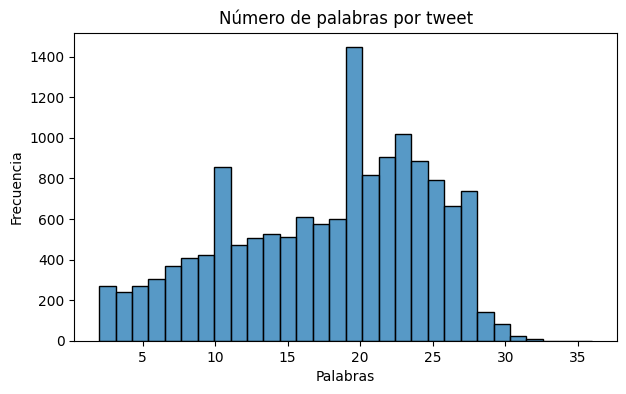

In [20]:
# Número de palabras de cada tweet
datos["num_palabras"] = datos["texto"].str.split().str.len()

print(datos["num_palabras"].describe())

plt.figure(figsize=(7, 4))
sns.histplot(data=datos, x="num_palabras", bins=30)
plt.title("Número de palabras por tweet")
plt.xlabel("Palabras")
plt.ylabel("Frecuencia")
plt.show()

In [21]:
#Ejemplos
for clase in ["negative", "neutral", "positive"]:
    print(f"--- {clase.upper()} ---")
    ejemplos = datos[datos["sentimiento"] == clase]["texto"].sample(3, random_state=SEMILLA)
    for tweet in ejemplos:
        print(f"  • {tweet}")
    print()

--- NEGATIVE ---
  • @JetBlue u guys have 2b kidding. No help anywhere. 5 hour delays? Still no answers. Bad cust service. #idlovetoask http://t.co/DPX3yoGTEj
  • @SouthwestAir crazy how every airline flew out to the northeast tonight except you
  • @JetBlue what else on this plane is duct-taped?? #ohboy #shouldigetoutandpush #airplane #flying… http://t.co/R9ZsVzuRLw

--- NEUTRAL ---
  • @SouthwestAir Hi! Winter Wx Advisory issued for STL. Snow &amp; Ice &amp; Cold, oh my! Will you issue a travel advisory for that?
  • @united I guess that's too much ask, huh?
  • @SouthwestAir please reply to my DM ♥️

--- POSITIVE ---
  • @SouthwestAir LOVE your TV ad with the girl dancing. Makes me laugh every time, AND now I want to take a trip! :-)
  • @AmericanAir Thanks! He is.
  • @united My favorite way to travel! Thank you! http://t.co/vGN2X1ckg0



- Se eliminaron 188 tweets duplicados, quedando **14,452 tweets**. Esto evita que un mismo
  tweet aparezca en entrenamiento y prueba (*data leakage*).
- **Desbalance de clases:** negative 62.9%, neutral 21.2%, positive 15.9%. Un modelo que
  siempre dijera "negative" tendría ~63% de *accuracy* sin aprender nada, por lo que ese
  valor será la **línea base** a superar, y además se evaluará con precision, recall y F1
  por clase, no solo con *accuracy*.
- **Longitud:** los tweets tienen en promedio 17.7 palabras (máximo 36), por el límite de
  caracteres de Twitter. Son secuencias cortas, adecuadas para una LSTM.
- **Ruido en el texto:** todos los tweets incluyen la mención a la aerolínea (`@united`),
  y muchos traen links (`http://t.co/...`), hashtags y entidades HTML (`&amp;`).
  Ninguno aporta al sentimiento, así que se limpian.

### 2.3 Limpieza del texto y separación de los datos
Antes de entrenar, el texto se limpia y los datos se dividen en tres conjuntos.

**Limpieza:** se aplica una función que convierte el texto a minúsculas y elimina menciones
(`@usuario`), links, entidades HTML, signos y emojis, conservando las palabras de los hashtags.
No se eliminan *stopwords*, porque palabras como "not" cambian el sentido de la frase y la
LSTM aprovecha el orden de las palabras.

**Separación:** los datos se dividen de forma **estratificada** (misma proporción de clases
en cada conjunto) en entrenamiento (70%), validación (15%) y prueba (15%).

In [22]:
import re
import html

def limpiar_texto(texto):
    texto = html.unescape(texto)                  # "&amp;" -> "&"
    texto = texto.lower()                         # todo a minúsculas
    texto = re.sub(r"@\w+", "", texto)            # quitar menciones (@united)
    texto = re.sub(r"http\S+", "", texto)         # quitar links
    texto = texto.replace("#", "")                # #ohboy -> ohboy (conserva la palabra) quitar gatos
    texto = re.sub(r"[^a-z0-9'\s]", " ", texto)   # quita signos y emojis
    texto = re.sub(r"\s+", " ", texto).strip()    # quita espacios de más
    return texto

# Probamos con un ejemplo antes de aplicarlo a todo
ejemplo = datos["texto"].iloc[3]
print(f"Antes:   {ejemplo}")
print(f"Después: {limpiar_texto(ejemplo)}")

Antes:   @VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse
Después: it's really aggressive to blast obnoxious entertainment in your guests' faces they have little recourse


In [24]:
datos["texto_limpio"] = datos["texto"].apply(limpiar_texto)

#revisamos si algún tweet quedó después de limpiar
vacios = (datos["texto_limpio"] == "").sum()
print(f"Tweets vacíos tras limpieza: {vacios}")
datos = datos[datos["texto_limpio"] != ""].reset_index(drop=True)
datos[["texto", "texto_limpio", "sentimiento"]].head()

Tweets vacíos tras limpieza: 0


,texto,texto_limpio,sentimiento
0,@VirginAmerica What @dhepburn said.,what said,neutral
1,@VirginAmerica plus you've added commercials t...,plus you've added commercials to the experienc...,positive
2,@VirginAmerica I didn't today... Must mean I n...,i didn't today must mean i need to take anothe...,neutral
3,@VirginAmerica it's really aggressive to blast...,it's really aggressive to blast obnoxious ente...,negative
4,@VirginAmerica and it's a really big bad thing...,and it's a really big bad thing about it,negative


#### Hallazgos: limpieza del texto
- La función `limpiar_texto` convierte a minúsculas y elimina menciones (`@usuario`), links,
  entidades HTML, signos y emojis, conservando la palabra de los hashtags y los apóstrofes
  (`don't`, `it's`).
- **Ningún tweet quedó vacío** tras la limpieza, así que no se perdieron datos.
- No se eliminaron *stopwords*: palabras como "not" invierten el sentido de una frase
  ("not good"), y la LSTM aprovecha el orden de las palabras.
- Al quitar los emojis se pierde algo de información (por ejemplo, ❤️ en un tweet positivo).
  Se queda como posible mejora a futuro.

In [25]:
from sklearn.model_selection import train_test_split

# Primero apartamos 15% para PRUEBA (no se toca hasta el final)
X_temp, X_prueba, y_temp, y_prueba = train_test_split(
    datos["texto_limpio"], datos["sentimiento"],
    test_size=0.15, stratify=datos["sentimiento"], random_state=SEMILLA)

# Del resto, separamos validación (15% del total ≈ 0.1765 de lo que queda)
X_entrena, X_valida, y_entrena, y_valida = train_test_split(
    X_temp, y_temp,
    test_size=0.1765, stratify=y_temp, random_state=SEMILLA)

print(f"Entrenamiento: {len(X_entrena)} tweets")
print(f"Validación:    {len(X_valida)} tweets")
print(f"Prueba:        {len(X_prueba)} tweets")

Entrenamiento: 10115 tweets
Validación:    2169 tweets
Prueba:        2168 tweets


#### Hallazgos: separación de los datos
| Conjunto | Tweets | % del total | Uso |
|---|---|---|---|
| Entrenamiento | 10,115 | 70% | Ajustar los pesos del modelo |
| Validación | 2,169 | 15% | Comparar versiones y ajustar hiperparámetros |
| Prueba | 2,168 | 15% | Evaluación final, se usa una sola vez |

- Los tamaños obtenidos coinciden con la proporción planeada **70/15/15**, lo que confirma
  que el segundo corte (0.1765 del 85% restante) dio un 15% del total para validación.
- La división es **estratificada**, por lo que los tres conjuntos conservan la proporción
  original de clases (≈63% negative, 21% neutral, 16% positive). Así, la evaluación en
  validación y prueba refleja la distribución real y ningún conjunto queda, por azar,
  con muy pocos tweets positivos.
- Se usan **tres conjuntos** porque, si se ajustaran los hiperparámetros viendo los
  resultados de prueba, el modelo terminaría adaptado a esos datos y la métrica final
  sería optimista. El conjunto de prueba queda apartado y solo se usará en la sección
  de Resultados, para medir con datos que el modelo y sus ajustes nunca vieron.
- 2,168 tweets de prueba son suficientes para que la métrica final sea confiable:
  incluso la clase minoritaria (*positive*) tendrá alrededor de 345 ejemplos.
- `random_state=SEMILLA` hace que la división sea la misma en cada ejecución, y con eso
  los resultados se pueden reproducir.

In [26]:
# La red necesita números, no texto
clases = ["negative", "neutral", "positive"]
etiqueta_a_numero = {clase: i for i, clase in enumerate(clases)}
print(f"Codificación: {etiqueta_a_numero}")

y_entrena_num = y_entrena.map(etiqueta_a_numero).values
y_valida_num  = y_valida.map(etiqueta_a_numero).values
y_prueba_num  = y_prueba.map(etiqueta_a_numero).values

print(f"Ejemplo: {y_entrena.iloc[0]} -> {y_entrena_num[0]}")

Codificación: {'negative': 0, 'neutral': 1, 'positive': 2}
Ejemplo: negative -> 0


In [27]:
from collections import Counter

# Contamos las palabras SOLO en entrenamiento
conteo_palabras = Counter(" ".join(X_entrena).split())
total = len(conteo_palabras)
frecuentes = sum(1 for c in conteo_palabras.values() if c >= 2)

print(f"Palabras distintas en entrenamiento: {total}")
print(f"Palabras que aparecen 2 veces o más: {frecuentes}")
print(f"\n10 palabras más comunes: {conteo_palabras.most_common(10)}")

# Largo de los tweets ya limpios
largos = X_entrena.str.split().str.len()
print(f"\nPercentil 95 de palabras: {np.percentile(largos, 95):.0f}")
print(f"Percentil 99 de palabras: {np.percentile(largos, 99):.0f}")

Palabras distintas en entrenamiento: 11027
Palabras que aparecen 2 veces o más: 5073

10 palabras más comunes: [('to', 6021), ('the', 4202), ('i', 3801), ('a', 3155), ('you', 2874), ('for', 2743), ('flight', 2723), ('and', 2636), ('on', 2597), ('my', 2287)]

Percentil 95 de palabras: 26
Percentil 99 de palabras: 28


#### Hallazgos: vocabulario y longitud
- En entrenamiento hay **11,027 palabras distintas**, pero solo **5,073 aparecen 2 veces o más**.
  Las demás (más de la mitad) aparecen una sola vez: errores de dedo, nombres propios,
  números de vuelo o palabras pegadas. Con un solo ejemplo, el modelo no puede aprender
  nada útil de ellas y solo agregarían ruido y parámetros.
- **Decisión: vocabulario de 5,000 palabras** (las más frecuentes). Las palabras fuera del
  vocabulario se representan con un token especial de "desconocido" (`[UNK]`).
- Las palabras más comunes son *stopwords* (to, the, i, a…). Aun así se conservan porque,
  como se explicó en la limpieza, aportan estructura a la frase y la LSTM lee el orden.
- Ya limpios, el 95% de los tweets tiene 26 palabras o menos y el 99% tiene 28 o menos.
- **Decisión: longitud de secuencia de 30

In [29]:
from tensorflow.keras.layers import TextVectorization

TAM_VOCABULARIO = 5000
LONGITUD_MAX = 30

vectorizador = TextVectorization(
    max_tokens=TAM_VOCABULARIO,
    output_mode="int",
    output_sequence_length=LONGITUD_MAX,
    standardize=None)   # ya limpiamos el texto con limpiar_texto

# Aprende el vocabulario SOLO con entrenamiento
vectorizador.adapt(X_entrena.values)

vocabulario = vectorizador.get_vocabulary()
print(f"Tamaño del vocabulario: {len(vocabulario)}")
print(f"Primeras 10 entradas: {vocabulario[:10]}")

Tamaño del vocabulario: 5000
Primeras 10 entradas: ['', '[UNK]', np.str_('to'), np.str_('the'), np.str_('i'), np.str_('a'), np.str_('you'), np.str_('for'), np.str_('flight'), np.str_('and')]


In [30]:
# Ejemplo de cómo se ve un tweet convertido
ejemplo = X_entrena.iloc[0]
print(f"Texto:     {ejemplo}")
print(f"Números:   {vectorizador([ejemplo]).numpy()[0]}")

# Convertimos los tres conjuntos
X_entrena_vec = vectorizador(X_entrena.values).numpy()
X_valida_vec  = vectorizador(X_valida.values).numpy()
X_prueba_vec  = vectorizador(X_prueba.values).numpy()

print(f"\nForma entrenamiento: {X_entrena_vec.shape}")
print(f"Forma validación:    {X_valida_vec.shape}")
print(f"Forma prueba:        {X_prueba_vec.shape}")

Texto:     you wanna help out how about you reimburse the money you cause my band to lose
Números:   [   6 1550   41   48   59   77    6 1466    3  392    6  689   11 1787
    2  685    0    0    0    0    0    0    0    0    0    0    0    0
    0    0]

Forma entrenamiento: (10115, 30)
Forma validación:    (2169, 30)
Forma prueba:        (2168, 30)


#### Hallazgos: vectorización del texto
- El vocabulario quedó en **5,000 entradas**: la posición 0 (`''`) es el relleno, la 1 es
  `[UNK]` (palabra desconocida) y del 2 en adelante están las palabras ordenadas por
  frecuencia. Entre las más comunes ya aparece *flight*, una palabra propia del dominio.
- En el ejemplo, el tweet de 15 palabras se convirtió en 15 números seguidos de 15 ceros
  de relleno. La palabra "you" aparece tres veces y siempre se codifica como 6: cada
  palabra tiene un identificador fijo.
- Los tres conjuntos quedaron como matrices de **(n_tweets, 30)**, el formato que recibe
  la red. Con esto los datos están listos para el modelo.

## 3. Desarrollo del modelo



### 3.1 Arquitectura base
Como primer modelo se construye una red **sencilla y sin regularización**, para tener un punto
de partida y diagnosticar su comportamiento antes de mejorarla:

| Capa | Función |
|---|---|
| `Embedding(5000, 64)` | Convierte cada número de palabra en un vector denso de 64 valores que se aprende durante el entrenamiento. Palabras con significado parecido terminan con vectores parecidos. |
| `LSTM(64)` | Capa recurrente que lee el tweet palabra por palabra, en orden, y guarda una "memoria" de lo leído. Esto le permite captar el contexto ("not good" ≠ "good"). |
| `Dense(3, softmax)` | Capa de salida: da la probabilidad de cada clase (negative, neutral, positive), y las tres suman 1. |

Se usa `mask_zero=True` en el Embedding para que la LSTM **ignore los ceros de relleno**
y solo procese las palabras reales.

In [31]:
from tensorflow.keras import layers

modelo_base = keras.Sequential([
    keras.Input(shape=(LONGITUD_MAX,)),
    layers.Embedding(input_dim=TAM_VOCABULARIO, output_dim=64, mask_zero=True),
    layers.LSTM(64),
    layers.Dense(3, activation="softmax")
], name="modelo_base")

modelo_base.summary()

Model: "modelo_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 30, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 353,219 (1.35 MB)

 Trainable params: 353,219 (1.35 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
modelo_base.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

#### Hallazgos: parámetros del modelo base
| Capa | Salida | Parámetros | De dónde salen |
|---|---|---|---|
| Embedding | (None, 30, 64) | 320,000 | 5,000 palabras × 64 valores por palabra |
| LSTM | (None, 64) | 33,024 | 4 compuertas × [64 × (64 entradas + 64 memoria) + 64 sesgos] |
| Dense | (None, 3) | 195 | 64 entradas × 3 clases + 3 sesgos |

- `None` en la salida es el tamaño del lote (*batch*), que puede variar.
- La LSTM tiene **4 compuertas** (olvido, entrada, candidata y salida), y por eso sus
  parámetros se multiplican por 4. Son las que deciden qué recordar y qué olvidar al
  leer cada palabra.
- **El 90% de los parámetros está en el Embedding.** El modelo tiene 353,219 parámetros
  y solo 10,115 tweets de entrenamiento, unos 35 parámetros por ejemplo. Con tanta
  capacidad y sin regularización, se espera que el modelo **memorice** los datos de
  entrenamiento (*overfitting*). Esto se verificará con las curvas de entrenamiento.

In [34]:
historial_base = modelo_base.fit(
    X_entrena_vec, y_entrena_num,
    validation_data=(X_valida_vec, y_valida_num),
    epochs=15,
    batch_size=64)

Epoch 1/15
159/159 ━━━━━━━━━━━━━━━━━━━━ 10s 45ms/step - accuracy: 0.6968 - loss: 0.7172 - val_accuracy: 0.7621 - val_loss: 0.5792
Epoch 2/15
159/159 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.8181 - loss: 0.4682 - val_accuracy: 0.7925 - val_loss: 0.5153
Epoch 3/15
159/159 ━━━━━━━━━━━━━━━━━━━━ 8s 53ms/step - accuracy: 0.8705 - loss: 0.3525 - val_accuracy: 0.7971 - val_loss: 0.5343
Epoch 4/15
159/159 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.8975 - loss: 0.2854 - val_accuracy: 0.7852 - val_loss: 0.5752
Epoch 5/15
159/159 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.9201 - loss: 0.2327 - val_accuracy: 0.7870 - val_loss: 0.6183
Epoch 6/15
159/159 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.9356 - loss: 0.1933 - val_accuracy: 0.7824 - val_loss: 0.7108
Epoch 7/15
159/159 ━━━━━━━━━━━━━━━━━━━━ 7s 42ms/step - accuracy: 0.9444 - loss: 0.1718 - val_accuracy: 0.7898 - val_loss: 0.7157
Epoch 8/15
159/159 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.9459 - loss: 0.1606 - val_acc

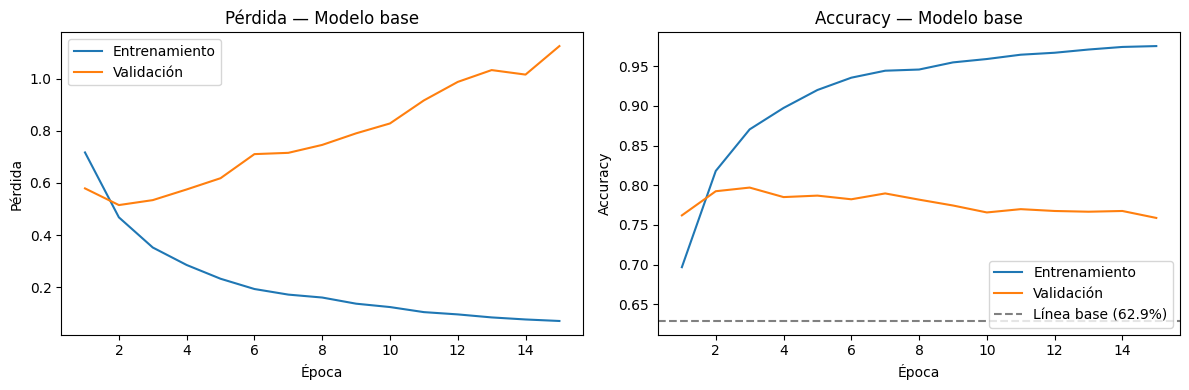

In [35]:
def graficar_historial(historial, titulo):
    h = historial.history
    epocas = range(1, len(h["loss"]) + 1)

    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

    ejes[0].plot(epocas, h["loss"], label="Entrenamiento")
    ejes[0].plot(epocas, h["val_loss"], label="Validación")
    ejes[0].set_title(f"Pérdida — {titulo}")
    ejes[0].set_xlabel("Época")
    ejes[0].set_ylabel("Pérdida")
    ejes[0].legend()

    ejes[1].plot(epocas, h["accuracy"], label="Entrenamiento")
    ejes[1].plot(epocas, h["val_accuracy"], label="Validación")
    ejes[1].axhline(0.629, color="gray", linestyle="--", label="Línea base (62.9%)")
    ejes[1].set_title(f"Accuracy — {titulo}")
    ejes[1].set_xlabel("Época")
    ejes[1].set_ylabel("Accuracy")
    ejes[1].legend()

    plt.tight_layout()
    plt.show()

graficar_historial(historial_base, "Modelo base")

### 3.2 Diagnóstico del modelo base
| Métrica (época 15) | Entrenamiento | Validación |
|---|---|---|
| Pérdida | 0.071 | 1.125 |
| Accuracy | 97.6% | 75.9% |

- **El modelo sí aprende:** desde la primera época supera la línea base de 62.9%, y su
  mejor *accuracy* de validación es **79.7% (época 3)**. La LSTM está captando información
  real del texto.
- **Pero presenta un overfitting severo:**
  - La pérdida de validación alcanza su mínimo en la **época 2 (0.515)** y a partir de ahí
    sube sin parar hasta 1.125, mientras que la de entrenamiento sigue bajando hasta 0.07.
  - La brecha final entre entrenamiento y validación es de **más de 21 puntos** de *accuracy*.
  - Después de la época 3, cada época extra **empeora** el desempeño con datos nuevos: el
    modelo deja de aprender patrones generales y empieza a memorizar tweets específicos.
- **Causas probables:**
  1. **Demasiada capacidad para pocos datos:** 353 mil parámetros para 10 mil tweets,
     el 90% en el Embedding.
  2. **Sin regularización:** nada impide que la red se ajuste al ruido de entrenamiento.
  3. **Demasiadas épocas:** se entrenó 15 épocas cuando el mejor punto fue la 2 o la 3.
- El *accuracy* global no muestra si el modelo reconoce bien las clases minoritarias.
  Por eso, a continuación se revisa el desempeño **por clase**.

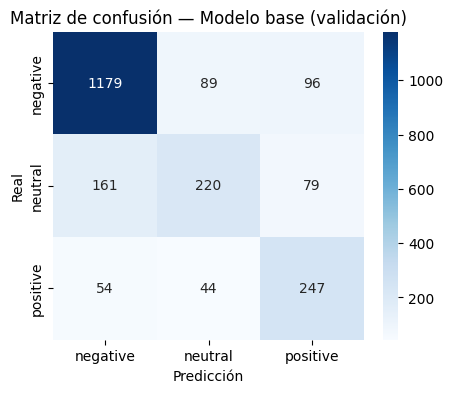

Accuracy: 0.7589
F1 macro: 0.6801

   clase  precision  recall     f1
negative     0.8458  0.8644 0.8550
 neutral     0.6232  0.4783 0.5412
positive     0.5853  0.7159 0.6441


In [36]:
from sklearn.metrics import confusion_matrix

def evaluar_modelo(modelo, X, y_real, titulo):
    # Probabilidades -> clase con mayor probabilidad
    probabilidades = modelo.predict(X, verbose=0)
    y_pred = np.argmax(probabilidades, axis=1)

    # Matriz de confusión
    matriz = confusion_matrix(y_real, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues",
                xticklabels=clases, yticklabels=clases)
    plt.title(f"Matriz de confusión — {titulo}")
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.show()

    # Métricas por clase, calculadas a mano
    resultados = []
    for i, clase in enumerate(clases):
        TP = matriz[i, i]                    # era la clase y se predijo bien
        FP = matriz[:, i].sum() - TP         # se predijo la clase, pero era otra
        FN = matriz[i, :].sum() - TP         # era la clase, pero se predijo otra
        precision = TP / (TP + FP) if (TP + FP) > 0 else 0
        recall    = TP / (TP + FN) if (TP + FN) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        resultados.append([clase, precision, recall, f1])

    tabla = pd.DataFrame(resultados, columns=["clase", "precision", "recall", "f1"])
    accuracy = np.trace(matriz) / matriz.sum()
    f1_macro = tabla["f1"].mean()

    print(f"Accuracy: {accuracy:.4f}")
    print(f"F1 macro: {f1_macro:.4f}\n")
    print(tabla.round(4).to_string(index=False))
    return accuracy, f1_macro

acc_base, f1_base = evaluar_modelo(modelo_base, X_valida_vec, y_valida_num, "Modelo base (validación)")

### 3.3 Desempeño por clase del modelo base (validación)
| Clase | Precision | Recall | F1 |
|---|---|---|---|
| negative | 0.846 | 0.864 | 0.855 |
| neutral | 0.623 | **0.478** | 0.541 |
| positive | 0.585 | 0.716 | 0.644 |
| **Accuracy** | | | **0.759** |
| **F1 macro** | | | **0.680** |

- **negative** es la clase que mejor reconoce (F1 0.855). Es también la que tiene más
  ejemplos, así que el modelo pudo aprenderla mejor.
- **neutral es el punto más débil:** solo encuentra el 47.8% de los tweets neutrales.
  En la matriz, **161 neutrales se clasificaron como negativos** y 79 como positivos.
  Tiene sentido: muchos tweets neutrales son preguntas o avisos ("please reply to my DM")
  sin palabras emocionales claras, y la frontera con las otras clases es difusa.
- **positive** tiene buen recall (71.6%) pero baja precision (58.5%): de los tweets que el
  modelo marca como positivos, muchos no lo son. **96 negativos se clasificaron como
  positivos**, posiblemente por sarcasmo ("thanks for the 5 hour delay").
- La diferencia entre el *accuracy* (0.759) y el **F1 macro (0.680)** confirma que el
  *accuracy* esconde el mal desempeño en las clases minoritarias. A partir de aquí,
  **el F1 macro de validación es la métrica principal** para comparar modelos.

## 4. Ajuste del modelo



Con base en el diagnóstico, se atacan los problemas uno a uno:

| Iteración | Problema que ataca | Cambios |
|---|---|---|
| 1 | Overfitting | Embedding más pequeño, Dropout y EarlyStopping |
| 2 | Bajo desempeño en clases minoritarias | Pesos por clase (*class weights*) y LSTM bidireccional |
| 3 | Aislar el efecto de la capa bidireccional | V1 + LSTM bidireccional, sin pesos por clase |

Cada versión se compara contra la anterior con el **F1 macro de validación**.

### 4.1 Iteración 1: regularización contra el overfitting
- **Embedding de 64 → 32 dimensiones:** el Embedding tenía el 90% de los parámetros.
  Reducirlo a la mitad le quita capacidad de memorizar sin quitarle vocabulario.
- **Dropout:** en cada paso de entrenamiento apaga al azar un porcentaje de neuronas
  (30% después del Embedding, 50% después de la LSTM). Así la red no puede depender de
  unas pocas neuronas o palabras específicas y se ve obligada a aprender patrones más
  generales. Solo actúa al entrenar; al predecir se usan todas las neuronas.
- **EarlyStopping:** vigila la pérdida de validación y detiene el entrenamiento si no
  mejora en 3 épocas seguidas, **regresando a los pesos de la mejor época**. Resuelve
  directamente el problema de entrenar de más que se vio en el modelo base.

In [37]:
# Aquí se va guardando cada versión para compararlas después
comparacion = [{"modelo": "Base", "accuracy": acc_base, "f1_macro": f1_base}]

In [38]:
from tensorflow.keras.callbacks import EarlyStopping

keras.utils.set_random_seed(SEMILLA)   # misma semilla para comparar en igualdad

modelo_v1 = keras.Sequential([
    keras.Input(shape=(LONGITUD_MAX,)),
    layers.Embedding(input_dim=TAM_VOCABULARIO, output_dim=32, mask_zero=True),
    layers.Dropout(0.3),
    layers.LSTM(64),
    layers.Dropout(0.5),
    layers.Dense(3, activation="softmax")
], name="modelo_v1")

modelo_v1.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

parada_temprana = EarlyStopping(monitor="val_loss", patience=3,
                                restore_best_weights=True, verbose=1)

historial_v1 = modelo_v1.fit(
    X_entrena_vec, y_entrena_num,
    validation_data=(X_valida_vec, y_valida_num),
    epochs=30,
    batch_size=64,
    callbacks=[parada_temprana])

Epoch 1/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.6708 - loss: 0.7666 - val_accuracy: 0.7367 - val_loss: 0.6181
Epoch 2/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.7822 - loss: 0.5489 - val_accuracy: 0.7870 - val_loss: 0.5369
Epoch 3/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.8380 - loss: 0.4283 - val_accuracy: 0.7976 - val_loss: 0.5104
Epoch 4/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.8671 - loss: 0.3629 - val_accuracy: 0.7990 - val_loss: 0.5224
Epoch 5/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.8871 - loss: 0.3134 - val_accuracy: 0.7958 - val_loss: 0.5420
Epoch 6/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.9013 - loss: 0.2809 - val_accuracy: 0.7958 - val_loss: 0.5620
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.


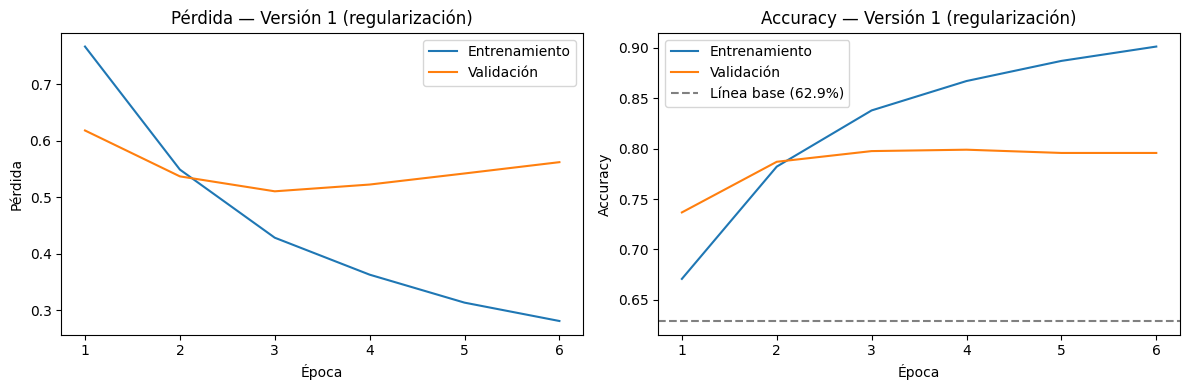

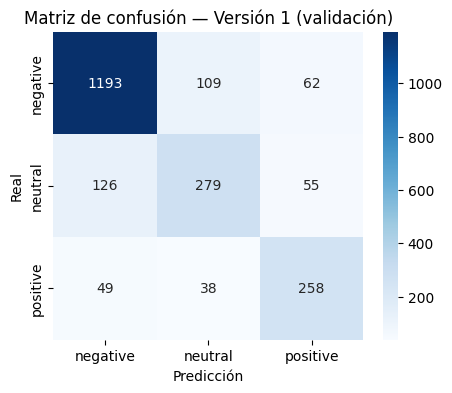

Accuracy: 0.7976
F1 macro: 0.7399

   clase  precision  recall     f1
negative     0.8721  0.8746 0.8734
 neutral     0.6549  0.6065 0.6298
positive     0.6880  0.7478 0.7167


In [39]:
graficar_historial(historial_v1, "Versión 1 (regularización)")

acc_v1, f1_v1 = evaluar_modelo(modelo_v1, X_valida_vec, y_valida_num, "Versión 1 (validación)")
comparacion.append({"modelo": "V1: Dropout + EarlyStopping", "accuracy": acc_v1, "f1_macro": f1_v1})

#### Resultados de la iteración 1
| Métrica (validación) | Base | V1 | Cambio |
|---|---|---|---|
| Accuracy | 0.759 | 0.798 | +3.9 pts |
| **F1 macro** | 0.680 | **0.740** | **+6.0 pts** |
| F1 negative | 0.855 | 0.873 | +1.8 pts |
| F1 neutral | 0.541 | 0.630 | +8.9 pts |
| F1 positive | 0.644 | 0.717 | +7.3 pts |

**¿Qué funcionó y por qué?**
- **EarlyStopping fue el cambio con más impacto.** Detuvo el entrenamiento en la época 6
  y restauró los pesos de la **época 3**, la de menor pérdida de validación. El modelo base
  tuvo un *accuracy* de validación parecido en su época 3 (79.7%), pero lo perdió al seguir
  entrenando hasta la 15. Es decir, gran parte de la mejora se debe a **detenerse a tiempo**.
- **Dropout y el Embedding más pequeño hicieron el overfitting más lento y suave.** En el
  base, la pérdida de validación subió de 0.51 a 1.12. En la V1, después de su mínimo,
  solo sube a 0.56. En la época elegida, la brecha de *accuracy* entre entrenamiento y
  validación es de unos 4 puntos, contra más de 21 en el base al final de su entrenamiento.
- **Las clases minoritarias fueron las más beneficiadas.** El F1 de *neutral* subió casi
  9 puntos y el de *positive* más de 7: un modelo que memoriza menos tiende menos a
  "irse por la mayoría".

**Lo que sigue fallando:** *neutral* sigue siendo la clase más débil (recall 0.607), y
126 tweets neutrales todavía se clasifican como negativos. El modelo sigue sesgado
hacia la clase mayoritaria, y eso es lo que ataca la siguiente iteración.

### 4.2 Iteración 2: clases desbalanceadas y contexto bidireccional
- **Pesos por clase (*class weights*):** durante el entrenamiento, equivocarse en un
  tweet de una clase minoritaria "cuesta" más en la pérdida que equivocarse en uno
  *negative*. El peso de cada clase es inversamente proporcional a su frecuencia:
  `peso = total / (n_clases × tweets_de_la_clase)`. Esto obliga al modelo a prestar
  más atención a *neutral* y *positive*, en lugar de favorecer a la mayoría.
- **LSTM bidireccional:** una LSTM normal lee el tweet de izquierda a derecha. La
  bidireccional usa dos LSTM, una en cada sentido, y combina lo que aprenden. Así, al
  interpretar una palabra conoce lo que viene antes **y después**, lo que ayuda con
  frases como "thanks... for nothing", donde el final cambia el sentido del inicio.
- Se mantienen el Dropout y el EarlyStopping de la iteración 1.

In [40]:
total = len(y_entrena_num)
n_clases = len(clases)

pesos_clase = {}
for i, clase in enumerate(clases):
    cantidad = (y_entrena_num == i).sum()
    pesos_clase[i] = total / (n_clases * cantidad)
    print(f"{clase}: {cantidad} tweets -> peso {pesos_clase[i]:.3f}")

negative: 6360 tweets -> peso 0.530
neutral: 2147 tweets -> peso 1.570
positive: 1608 tweets -> peso 2.097


In [41]:
from tensorflow.keras.layers import Bidirectional

keras.utils.set_random_seed(SEMILLA)

modelo_v2 = keras.Sequential([
    keras.Input(shape=(LONGITUD_MAX,)),
    layers.Embedding(input_dim=TAM_VOCABULARIO, output_dim=32, mask_zero=True),
    layers.Dropout(0.3),
    Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.5),
    layers.Dense(3, activation="softmax")
], name="modelo_v2")

modelo_v2.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

parada_temprana = EarlyStopping(monitor="val_loss", patience=3,
                                restore_best_weights=True, verbose=1)

historial_v2 = modelo_v2.fit(
    X_entrena_vec, y_entrena_num,
    validation_data=(X_valida_vec, y_valida_num),
    epochs=30,
    batch_size=64,
    class_weight=pesos_clase,
    callbacks=[parada_temprana])

modelo_v2.summary()

Epoch 1/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 16s 64ms/step - accuracy: 0.6500 - loss: 0.9173 - val_accuracy: 0.6856 - val_loss: 0.7644
Epoch 2/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 0.7793 - loss: 0.5892 - val_accuracy: 0.7427 - val_loss: 0.6235
Epoch 3/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 8s 49ms/step - accuracy: 0.8254 - loss: 0.4555 - val_accuracy: 0.7243 - val_loss: 0.6856
Epoch 4/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 0.8566 - loss: 0.3815 - val_accuracy: 0.7146 - val_loss: 0.7243
Epoch 5/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 9s 57ms/step - accuracy: 0.8783 - loss: 0.3207 - val_accuracy: 0.7709 - val_loss: 0.6252
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.


Model: "modelo_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 30, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        49,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 630,155 (2.40 MB)

 Trainable params: 210,051 (820.51 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 420,104 (1.60 MB)

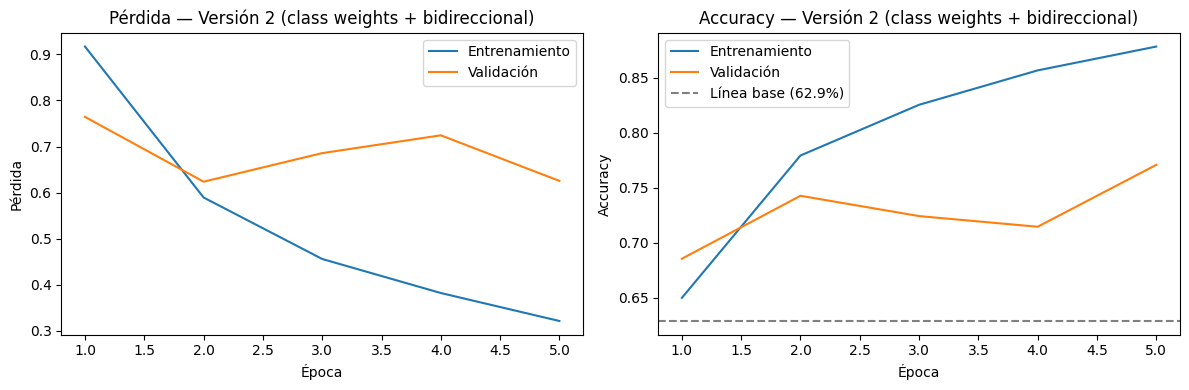

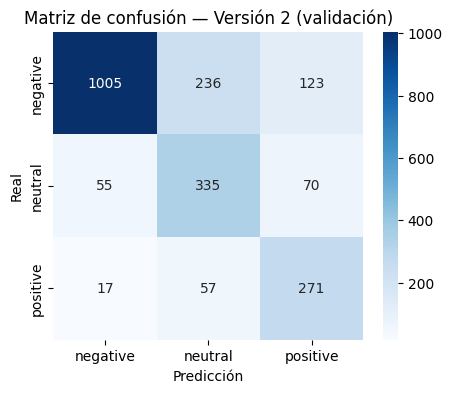

Accuracy: 0.7427
F1 macro: 0.7031

   clase  precision  recall     f1
negative     0.9331  0.7368 0.8234
 neutral     0.5334  0.7283 0.6158
positive     0.5841  0.7855 0.6700


In [42]:
graficar_historial(historial_v2, "Versión 2 (class weights + bidireccional)")

acc_v2, f1_v2 = evaluar_modelo(modelo_v2, X_valida_vec, y_valida_num, "Versión 2 (validación)")
comparacion.append({"modelo": "V2: + Class weights + Bidireccional", "accuracy": acc_v2, "f1_macro": f1_v2})

#### Resultados de la iteración 2
| Métrica (validación) | V1 | V2 | Cambio |
|---|---|---|---|
| Accuracy | 0.798 | 0.743 | −5.5 pts |
| **F1 macro** | **0.740** | 0.703 | **−3.7 pts** |
| Recall negative | 0.875 | 0.737 | −13.8 pts |
| Recall neutral | 0.607 | 0.728 | +12.1 pts |
| Recall positive | 0.748 | 0.786 | +3.8 pts |
| Precision neutral | 0.655 | 0.533 | −12.2 pts |

**Esta iteración no mejoró el modelo.** Análisis:
- **Los pesos por clase cumplieron su objetivo, pero en exceso.** El recall de *neutral*
  subió 12 puntos, pero el modelo pasó a confundir muchos tweets negativos con neutrales
  (236 contra 109 en la V1). Como *negative* es el 63% de los datos, la pérdida de
  precisión ahí pesa más que la ganancia en las clases minoritarias.
- **La validación se volvió inestable** (la pérdida sube y baja entre épocas) y el
  EarlyStopping eligió la época 2, muy temprano. Una causa es que Keras aplica
  `class_weight` solo a la pérdida de entrenamiento: la pérdida de validación que vigila
  el EarlyStopping no está ponderada, así que ambas miden cosas distintas.
-

### 4.3 Iteración 3: aislar el efecto de la capa bidireccional
Para corregir el error de metodología, se parte de la V1 (el mejor modelo hasta ahora)
y se cambia **una sola cosa**: la LSTM pasa a ser bidireccional, **sin** pesos por clase.
- Si mejora a la V1: la capa bidireccional sí aporta, y la caída de la V2 se debió a los
  pesos por clase.
- Si no mejora: el contexto en ambos sentidos no ayuda en textos tan cortos, y la V1
  se mantiene como mejor modelo.

In [43]:
keras.utils.set_random_seed(SEMILLA)

modelo_v3 = keras.Sequential([
    keras.Input(shape=(LONGITUD_MAX,)),
    layers.Embedding(input_dim=TAM_VOCABULARIO, output_dim=32, mask_zero=True),
    layers.Dropout(0.3),
    Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.5),
    layers.Dense(3, activation="softmax")
], name="modelo_v3")

modelo_v3.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

parada_temprana = EarlyStopping(monitor="val_loss", patience=3,
                                restore_best_weights=True, verbose=1)

historial_v3 = modelo_v3.fit(
    X_entrena_vec, y_entrena_num,
    validation_data=(X_valida_vec, y_valida_num),
    epochs=30,
    batch_size=64,
    callbacks=[parada_temprana])      # ← sin class_weight

Epoch 1/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 20s 78ms/step - accuracy: 0.6833 - loss: 0.7499 - val_accuracy: 0.7529 - val_loss: 0.5964
Epoch 2/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 8s 49ms/step - accuracy: 0.8000 - loss: 0.5078 - val_accuracy: 0.8031 - val_loss: 0.5153
Epoch 3/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 11s 54ms/step - accuracy: 0.8496 - loss: 0.3975 - val_accuracy: 0.7967 - val_loss: 0.5226
Epoch 4/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 11s 59ms/step - accuracy: 0.8764 - loss: 0.3341 - val_accuracy: 0.7985 - val_loss: 0.5245
Epoch 5/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 0.8913 - loss: 0.2912 - val_accuracy: 0.8013 - val_loss: 0.5595
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.


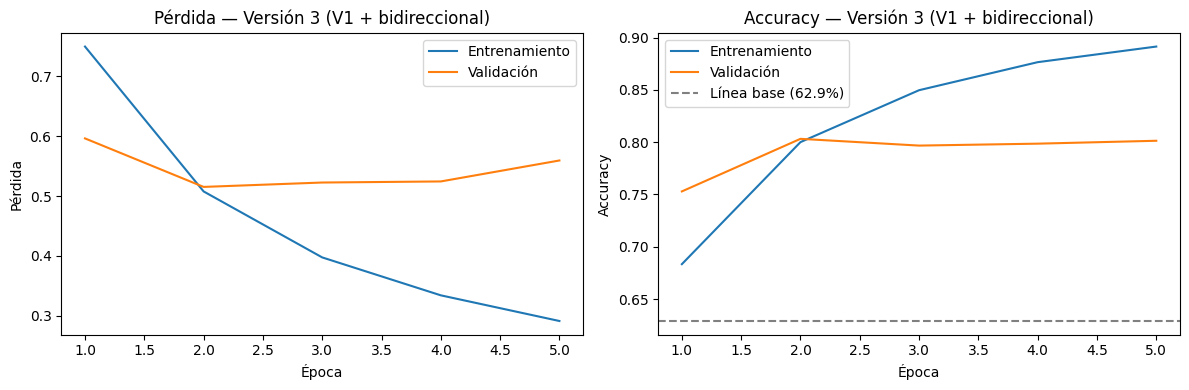

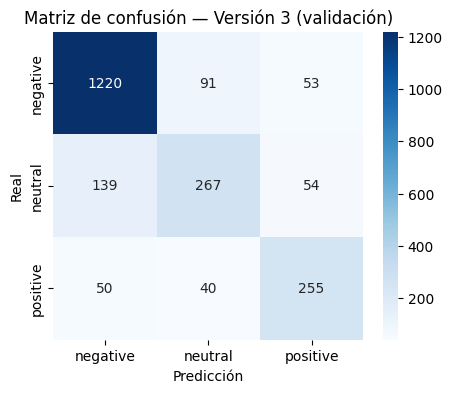

Accuracy: 0.8031
F1 macro: 0.7412

   clase  precision  recall     f1
negative     0.8659  0.8944 0.8799
 neutral     0.6709  0.5804 0.6224
positive     0.7044  0.7391 0.7214


In [44]:
graficar_historial(historial_v3, "Versión 3 (V1 + bidireccional)")

acc_v3, f1_v3 = evaluar_modelo(modelo_v3, X_valida_vec, y_valida_num, "Versión 3 (validación)")
comparacion.append({"modelo": "V3: V1 + Bidireccional", "accuracy": acc_v3, "f1_macro": f1_v3})

#### Resultados de la iteración 3
| Métrica (validación) | V1 | V3 | Cambio |
|---|---|---|---|
| Accuracy | 0.798 | 0.803 | +0.5 pts |
| F1 macro | 0.740 | 0.741 | +0.1 pts |
| F1 negative | 0.873 | 0.880 | +0.7 pts |
| F1 neutral | 0.630 | 0.622 | −0.8 pts |
| F1 positive | 0.717 | 0.721 | +0.4 pts |

- **La capa bidireccional no produce una mejora significativa.** Una diferencia de
  0.5 puntos de *accuracy* equivale a unos 11 tweets de 2,169, dentro de la variación
  normal entre entrenamientos con distinta inicialización.
- Una explicación posible es que los tweets son **muy cortos** (~17 palabras): una LSTM
  que lee en un solo sentido ya alcanza a "recordar" todo el tweet, así que leerlo
  también al revés aporta poca información nueva. En textos largos (reseñas, artículos)
  la bidireccional suele ayudar más.
- Este experimento confirma que **la caída de la V2 se debió a los pesos por clase**, no a
  la capa bidireccional, porque la V3 es la V2 sin `class_weight` y recuperó el desempeño.

                             modelo  accuracy  f1_macro
                               Base    0.7589    0.6801
        V1: Dropout + EarlyStopping    0.7976    0.7399
V2: + Class weights + Bidireccional    0.7427    0.7031
             V3: V1 + Bidireccional    0.8031    0.7412


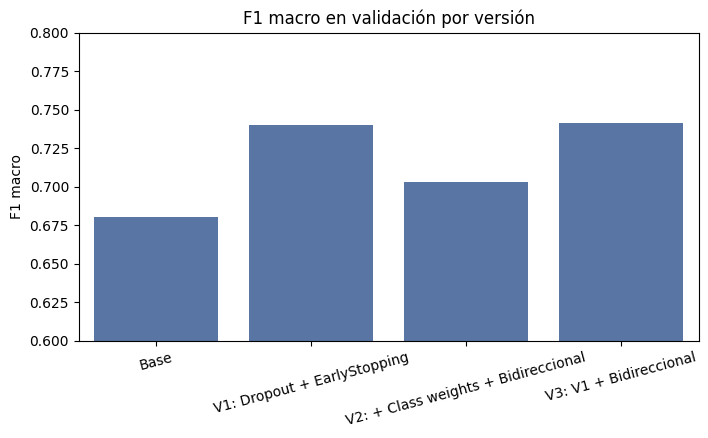

In [45]:
tabla_comparacion = pd.DataFrame(comparacion)
print(tabla_comparacion.round(4).to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(data=tabla_comparacion, x="modelo", y="f1_macro", color="#4c72b0")
plt.title("F1 macro en validación por versión")
plt.ylabel("F1 macro")
plt.xlabel("")
plt.ylim(0.6, 0.8)
plt.xticks(rotation=15)
plt.show()

### 4.4 Elección del modelo final
| Versión | Cambio | F1 macro (validación) |
|---|---|---|
| Base | Embedding 64 + LSTM 64, sin regularización | 0.680 |
| **V1** | **Embedding 32 + Dropout + EarlyStopping** | **0.740** |
| V2 | V1 + class weights + bidireccional | 0.703 |
| V3 | V1 + bidireccional | 0.741 |

**Se elige la V1 como modelo final**, aunque la V3 tiene un F1 macro 0.1 puntos mayor:
- La diferencia entre ambas no es significativa.
- La V1 tiene **menos parámetros** (185 mil contra 210 mil) y entrena más rápido.
- La V1 tiene mejor F1 en *neutral*, la clase más difícil.
- Ante dos modelos con desempeño equivalente, se prefiere el más simple
  (principio de parsimonia), porque tiende a generalizar mejor.

**Resumen de lo que funcionó:** la regularización (EarlyStopping + Dropout + Embedding
más pequeño) fue el único cambio con una mejora clara (**+6 puntos de F1 macro**), porque
atacó el problema principal del modelo base: el overfitting. Los pesos por clase
corrigieron de más y la capa bidireccional no aportó en textos tan cortos.

## 5. Resultados


Se evalúa el modelo final (V1) con el **conjunto de prueba**, que no se usó en ningún
momento del entrenamiento ni de la elección de hiperparámetros. Este es el estimado
honesto de cómo funcionaría el modelo con tweets nuevos.

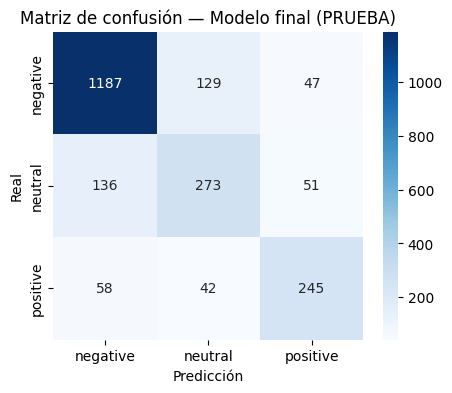

Accuracy: 0.7864
F1 macro: 0.7271

   clase  precision  recall     f1
negative     0.8595  0.8709 0.8652
 neutral     0.6149  0.5935 0.6040
positive     0.7143  0.7101 0.7122


In [46]:
modelo_final = modelo_v1

acc_prueba, f1_prueba = evaluar_modelo(modelo_final, X_prueba_vec, y_prueba_num,
                                       "Modelo final (PRUEBA)")

In [47]:
modelo_final.save("modelo_final.keras")

# Comprobamos que se guardó bien: lo cargamos y predecimos
modelo_cargado = keras.models.load_model("modelo_final.keras")
iguales = np.allclose(modelo_final.predict(X_prueba_vec[:5], verbose=0),
                      modelo_cargado.predict(X_prueba_vec[:5], verbose=0))
print(f"¿El modelo cargado predice igual que el original? {iguales}")

¿El modelo cargado predice igual que el original? True


### 5.1 Desempeño del modelo final en el conjunto de prueba
| Clase | Precision | Recall | F1 |
|---|---|---|---|
| negative | 0.860 | 0.871 | 0.865 |
| neutral | 0.615 | 0.594 | 0.604 |
| positive | 0.714 | 0.710 | 0.712 |
| **Accuracy** | | | **0.786** |
| **F1 macro** | | | **0.727** |

**Comparación con validación:**
| Métrica | Validación | Prueba |
|---|---|---|
| Accuracy | 0.798 | 0.786 |
| F1 macro | 0.740 | 0.727 |

- En prueba, el modelo obtiene **78.6% de accuracy**, casi **16 puntos por encima de la
  línea base** (62.9%, siempre predecir *negative*).
- La caída respecto a validación es de apenas ~1 punto. Era de esperarse, porque
  validación se usó para elegir el modelo y por eso es ligeramente optimista. Una
  diferencia tan pequeña indica que **el modelo generaliza bien a tweets que nunca vio**.
- El patrón por clase se mantiene igual que en validación: *negative* es la clase
  más fácil (F1 0.865), *positive* queda en un nivel intermedio (0.712) y *neutral*
  sigue siendo la más difícil (0.604).
- **El error más frecuente** sigue siendo la confusión entre *neutral* y *negative*:
  136 neutrales se predijeron como negativos y 129 negativos como neutrales. Los
  errores entre *negative* y *positive* (47 y 58) son menos comunes: al modelo le
  cuesta más distinguir la intensidad del sentimiento que su dirección.

## 6. Conclusiones


**Sobre el resultado:** se construyó un clasificador de sentimiento basado en una LSTM que,
con datos de prueba nunca vistos, alcanza un **accuracy de 78.6% y un F1 macro de 0.727**,
superando claramente a la línea base de 62.9%. El modelo es confiable para detectar quejas
(*negative*, F1 0.865), que en la práctica es el caso de uso más valioso para una aerolínea.

**Sobre el proceso de ajuste:**
- El modelo base mostró un **overfitting severo** (97.6% en entrenamiento contra 75.9% en
  validación). El cambio que más mejoró al modelo fue la **regularización**: EarlyStopping
  para detenerse en la mejor época, y Dropout con un Embedding más pequeño para frenar la
  memorización. En conjunto subieron el F1 macro de 0.680 a 0.740.
- Los **pesos por clase** mejoraron el recall de las clases minoritarias, pero corrigieron
  de más y empeoraron el F1 macro (0.703).
- La **LSTM bidireccional** no aportó una mejora significativa (0.741 contra 0.740), muy
  probablemente porque los tweets son demasiado cortos para aprovechar el contexto en
  ambos sentidos.
- Cambiar una sola variable por iteración fue clave para entender el efecto de cada
  cambio. La iteración 3 permitió atribuir la caída de la V2 a los pesos por clase.

**Limitaciones:**
- La clase **neutral** sigue siendo el punto débil (F1 0.604). Muchos tweets neutrales son
  preguntas o avisos con poco contenido emocional, y la frontera con las otras clases es
  ambigua incluso para las personas que etiquetaron los datos.
- El modelo no entiende bien el **sarcasmo** ("thanks for the 5 hour delay"), porque
  contiene palabras positivas con intención negativa.
- Los datos son de **2015 y en inglés**, sobre aerolíneas de EE. UU. El modelo podría no
  funcionar igual con otro idioma, otra industria o el lenguaje actual de redes sociales.

**Posibles áreas de mejora:**
1. **Embeddings preentrenados** (GloVe o Word2Vec entrenados con millones de tweets): el
   modelo empezaría ya "sabiendo" el significado de las palabras, en lugar de aprenderlo
   solo con 10 mil tweets.
2. **Modelos tipo Transformer** (BERT, RoBERTa), que hoy son el estado del arte en
   análisis de sentimiento y manejan mejor el contexto y el sarcasmo.
3. **Conservar los emojis**, convirtiéndolos a palabras (❤️ → "heart") en lugar de
   eliminarlos, porque suelen tener un sentimiento muy claro.
4. **Pesos por clase más suaves**, por ejemplo la raíz cuadrada de los pesos actuales,
   para ayudar a las clases minoritarias sin corregir de más.
5. **Más datos de la clase neutral** o técnicas de aumento de datos para texto.

In [49]:
with open("vocabulario.txt", "w", encoding="utf-8") as archivo:
    for palabra in vectorizador.get_vocabulary():
        archivo.write(palabra + "\n")

print("Vocabulario guardado en vocabulario.txt")

Vocabulario guardado en vocabulario.txt


## 7. Aplicación


La función `predecir_sentimiento` recibe el texto de un tweet nuevo y regresa su
sentimiento y la probabilidad de cada clase. Carga el modelo y el vocabulario desde los
archivos guardados, por lo que funciona sin necesidad de volver a entrenar.

In [50]:
# Cargamos el modelo y el vocabulario desde los archivos
modelo_app = keras.models.load_model("modelo_final.keras")

with open("vocabulario.txt", encoding="utf-8") as archivo:
    vocab_app = [linea.rstrip("\n") for linea in archivo]

vectorizador_app = TextVectorization(
    output_mode="int",
    output_sequence_length=LONGITUD_MAX,
    standardize=None)
vectorizador_app.set_vocabulary(vocab_app[2:])   # sin '' ni [UNK], Keras los agrega solo

def predecir_sentimiento(texto):
    texto_limpio = limpiar_texto(texto)
    secuencia = vectorizador_app([texto_limpio])
    probabilidades = modelo_app.predict(secuencia, verbose=0)[0]
    clase = clases[np.argmax(probabilidades)]

    print(f"Tweet: {texto}")
    print(f"Sentimiento: {clase.upper()}")
    for nombre, prob in zip(clases, probabilidades):
        print(f"   {nombre}: {prob:.1%}")
    print()
    return clase

In [51]:
tweets_nuevos = [
    "@united my flight was delayed 4 hours and nobody told us anything",
    "@JetBlue thank you for the amazing service, the crew was super friendly!",
    "@AmericanAir what time does the flight to Chicago board?",
    "@SouthwestAir the food was not good at all",
    "@Delta thanks for losing my luggage again, great job",
]

for tweet in tweets_nuevos:
    predecir_sentimiento(tweet)

Tweet: @united my flight was delayed 4 hours and nobody told us anything
Sentimiento: NEGATIVE
   negative: 99.5%
   neutral: 0.4%
   positive: 0.1%

Tweet: @JetBlue thank you for the amazing service, the crew was super friendly!
Sentimiento: POSITIVE
   negative: 0.2%
   neutral: 0.4%
   positive: 99.4%

Tweet: @AmericanAir what time does the flight to Chicago board?
Sentimiento: NEUTRAL
   negative: 31.5%
   neutral: 57.9%
   positive: 10.6%

Tweet: @SouthwestAir the food was not good at all
Sentimiento: POSITIVE
   negative: 38.2%
   neutral: 19.3%
   positive: 42.5%

Tweet: @Delta thanks for losing my luggage again, great job
Sentimiento: POSITIVE
   negative: 14.5%
   neutral: 7.5%
   positive: 77.9%



### 7.1 Análisis de las predicciones
| Tweet de prueba | Esperado | Predicción | Confianza | ¿Correcto? |
|---|---|---|---|---|
| Queja por retraso de 4 horas | negative | negative | 99.5% | ✅ |
| Elogio a la tripulación | positive | positive | 99.4% | ✅ |
| Pregunta por la hora de abordaje | neutral | neutral | 57.9% | ✅ |
| "the food was **not good** at all" | negative | positive | 42.5% | ❌ |
| "thanks for losing my luggage, great job" (sarcasmo) | negative | positive | 77.9% | ❌ |

- En los casos claros (queja y elogio) el modelo acierta con más de 99% de confianza.
- En la **pregunta neutral** acierta, pero con solo 57.9%: refleja que *neutral* es la
  clase más difícil, como se vio en la evaluación.
- **Negación:** el modelo falla con "not good". Las probabilidades quedan casi empatadas
  (42.5% positive contra 38.2% negative), lo que indica que el modelo está inseguro: la
  LSTM detecta algo de negatividad, pero no alcanza a aprender bien que "not" invierte
  a "good" con solo ~10 mil tweets de entrenamiento.
- **Sarcasmo:** "thanks" y "great job" son palabras que el modelo asocia fuertemente con
  *positive*, y no logra captar la ironía. Confirma la limitación señalada en las conclusiones.
- Estos dos errores refuerzan las propuestas de mejora: los **embeddings preentrenados**
  o los **Transformers** (BERT) aprenden con millones de textos y manejan mucho mejor la
  negación y el sarcasmo.

### Limitaciones
   - Le cuesta manejar la **negación** ("not good" se clasificó como positivo), a pesar de
     haber conservado las *stopwords*: con pocos datos, la LSTM no aprende de forma confiable
     cómo "not" cambia el sentido de la siguiente palabra.